# **Details:**

**Name:** Vinit Jadhav

**PRN:** 202401040163

**Division:** A

**Roll No.:** 38


# **Title**

Practical Assignment 06 – Clustering Algorithms

# **Aim**

To implement clustering algorithms on a real-world dataset to identify meaningful groups in the data and evaluate clustering quality using Silhouette Score, Davies-Bouldin Index, and visual inspection.

# **Experiment Objectives**

- To understand the concept of unsupervised learning and clustering.
- To load and explore a real-world dataset.
- To preprocess and scale the features before clustering.
- To implement K-Means, Agglomerative (Hierarchical), and DBSCAN clustering algorithms.
- To identify groups of similar observations without using target labels during model training.
- To evaluate clustering quality using Silhouette Score and Davies-Bouldin Index.
- To visualize clusters using Principal Component Analysis (PCA).
- To compare the strengths, limitations, and suitable applications of each algorithm.

# **Experiment Outcome**

- Loaded and explored the Wine dataset.
- Standardized the input features for distance-based clustering.
- Applied K-Means, Agglomerative Clustering, and DBSCAN.
- Evaluated valid clustering results using Silhouette Score and Davies-Bouldin Index.
- Used PCA to visualize high-dimensional data in two dimensions.
- Compared cluster assignments and the number of clusters produced by each algorithm.
- Identified the advantages, limitations, and practical use cases of clustering methods.

# **Theory**

### 1. Clustering

Clustering is an unsupervised Machine Learning technique that groups similar data points together. It does not require predefined class labels during training. The goal is to discover natural groupings or patterns in data.

Examples include customer segmentation, document grouping, image segmentation, and grouping similar products.

### 2. K-Means Clustering

K-Means divides data into a specified number of clusters, represented by centroids. It repeatedly assigns each observation to its nearest centroid and updates the centroids until assignments stabilize or the iteration limit is reached.

**Advantages:** Simple, fast, and works well when clusters are compact and reasonably separated.

**Limitations:** The number of clusters must be selected in advance; results can depend on initialization and it is sensitive to outliers and feature scales.

### 3. Agglomerative (Hierarchical) Clustering

Agglomerative clustering starts with each observation as its own cluster and repeatedly merges the closest clusters. The process creates a hierarchy of clusters. The number of clusters can be selected by setting a distance threshold or specifying the desired number.

**Advantages:** Does not require centroid-based assumptions and can reveal hierarchical structure.

**Limitations:** Can be computationally expensive for large datasets and results depend on the linkage method and distance metric.

### 4. DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) groups points that are closely packed together. It uses two main parameters: `eps`, the neighborhood radius, and `min_samples`, the minimum number of points needed to form a dense region. Points that do not belong to a dense region may be marked as noise (`-1`).

**Advantages:** Can identify irregularly shaped clusters and detect noise without specifying the number of clusters in advance.

**Limitations:** Choosing parameters can be difficult; performance may be poor when clusters have very different densities or when feature dimensions are high.

### 5. Clustering Evaluation Metrics

- **Silhouette Score:** Measures how similar a point is to its own cluster compared with other clusters. Values range from -1 to 1; higher values generally indicate better-separated clusters.
- **Davies-Bouldin Index:** Measures similarity between clusters based on within-cluster spread and separation. Lower values generally indicate better clustering.
- **Visual Inspection:** A scatter plot can help inspect separation and overlap. Since the dataset has many features, PCA is used to project it into two dimensions for visualization.

These metrics evaluate cluster structure, not whether the groups have real-world meaning. Domain knowledge is still required to interpret clusters.

### 6. Dataset Used

The experiment uses the Wine recognition dataset available in scikit-learn. It contains 178 wine observations described by 13 numerical chemical measurements. The original dataset includes three wine classes, but those labels are not used to train the clustering algorithms. Clustering is performed only on the feature measurements.

The original labels may be used after clustering only for an optional external comparison, not to build the clusters.

# **Problem Statement**

Apply unsupervised clustering algorithms to the Wine dataset to discover groups of observations with similar chemical measurements.

The following algorithms are implemented:

1. K-Means Clustering
2. Agglomerative (Hierarchical) Clustering
3. DBSCAN Clustering

Scale the feature values before clustering. Evaluate the resulting clusters using Silhouette Score and Davies-Bouldin Index where the metric is mathematically valid. Use PCA scatter plots for visual inspection and compare the algorithms based on their cluster structure, number of clusters, and noise points.

# **1. Import Required Libraries**

Import the libraries required for data handling, visualization, preprocessing, clustering, dimensionality reduction, and evaluation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


# **2. Load and Understand the Dataset**

Load the Wine dataset and inspect its dimensions, feature names, first few records, and summary statistics. The target labels are kept separate and are not used during clustering.

In [ ]:
wine = load_wine(as_frame=True)

X = wine.data
original_labels = wine.target  # Reserved only for optional external comparison.

df = X.copy()

print("Dataset shape:", df.shape)
print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])
print("\nFeature names:")
print(list(X.columns))

print("\nFirst five records:")
display(df.head())

print("\nDescriptive statistics:")
display(df.describe().round(2))

print("\nOriginal class labels are not used to train clustering models.")

Dataset shape: (178, 13)
Number of observations: 178
Number of features: 13

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

First five records:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Descriptive statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00



Original class labels are not used to train clustering models.


# **3. Exploratory Data Analysis**

Check missing values and inspect the feature distributions. Since the features have different measurement scales, standardization is required before applying distance-based clustering algorithms.

Missing values in each feature:


,Missing Values
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0



Feature means and standard deviations:


,mean,std
alcohol,13.00,0.81
malic_acid,2.34,1.12
ash,2.37,0.27
alcalinity_of_ash,19.49,3.34
magnesium,99.74,14.28
total_phenols,2.30,0.63
flavanoids,2.03,1.00
nonflavanoid_phenols,0.36,0.12
proanthocyanins,1.59,0.57
color_intensity,5.06,2.32


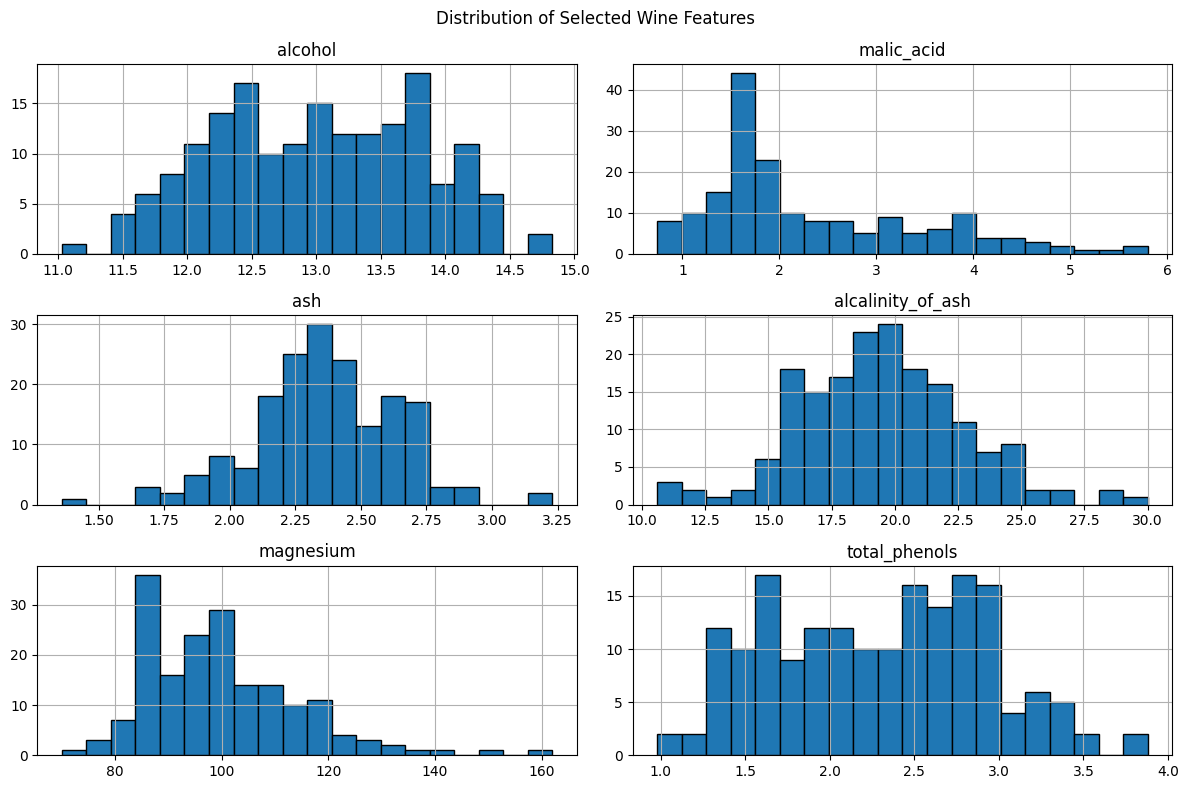

In [ ]:
print("Missing values in each feature:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nFeature means and standard deviations:")
display(df.agg(["mean", "std"]).T.round(2))

df.iloc[:, :6].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distribution of Selected Wine Features")
plt.tight_layout()
plt.show()

# **4. Data Preprocessing and Feature Scaling**

Standardize the features so that measurements with larger numerical ranges do not dominate distance calculations. The scaler is fitted to the feature dataset because this is an unsupervised exploratory clustering exercise.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)
print("\nScaled feature means (approximately zero):")
print(np.round(X_scaled.mean(axis=0), 3))
print("\nScaled feature standard deviations (approximately one):")
print(np.round(X_scaled.std(axis=0), 3))

Original feature shape: (178, 13)
Scaled feature shape: (178, 13)

Scaled feature means (approximately zero):
[-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]

Scaled feature standard deviations (approximately one):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# **5. Select the Number of Clusters for K-Means**

Use the Elbow Method and Silhouette Score to examine candidate values of K. The Elbow Method compares within-cluster sum of squares (inertia), while Silhouette Score measures cluster separation.

The best K should not be selected using one metric alone. Interpret the plots and the practical context together.

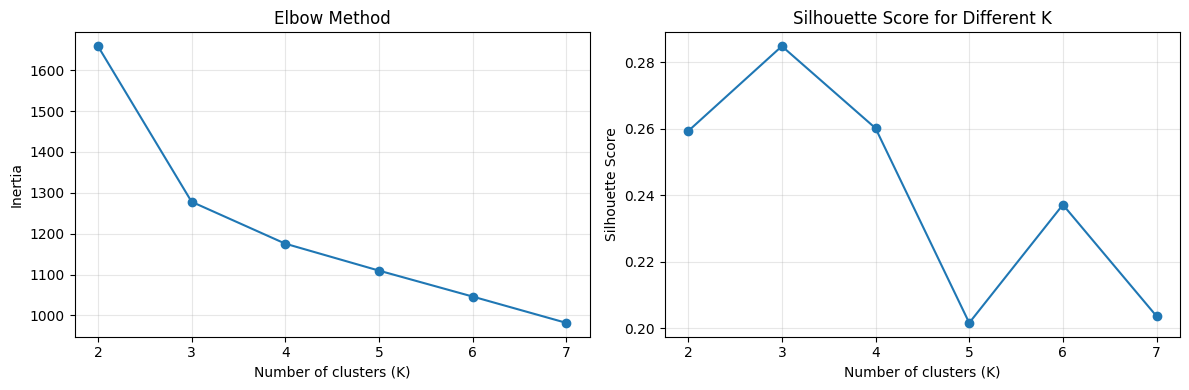

,K,Inertia,Silhouette Score
0,2,1658.7589,0.2593
1,3,1277.9285,0.2849
2,4,1175.4283,0.2602
3,5,1109.5127,0.2016
4,6,1046.0023,0.2372
5,7,981.5952,0.2036


Selected K based on the highest tested Silhouette Score: 3


In [ ]:
k_values = range(2, 8)
inertias = []
silhouette_values = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_values), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score for Different K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_values
})
display(k_results.round(4))

selected_k = int(k_results.loc[k_results["Silhouette Score"].idxmax(), "K"])
print("Selected K based on the highest tested Silhouette Score:", selected_k)

# **6. Implement K-Means Clustering**

Apply K-Means using the selected number of clusters. Each observation is assigned to the nearest cluster centroid.

In [ ]:
kmeans = KMeans(
    n_clusters=selected_k,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("Number of clusters:", len(np.unique(kmeans_labels)))
print("\nCluster sizes:")
display(pd.Series(kmeans_labels).value_counts().sort_index().to_frame("Number of Observations"))

K-Means clustering completed.
Number of clusters: 3

Cluster sizes:


,Number of Observations
0,65
1,51
2,62


# **7. Implement Agglomerative Clustering**

Apply Agglomerative Clustering using the same number of clusters selected for K-Means. Ward linkage is used because it merges clusters to minimize the increase in within-cluster variance.

In [ ]:
agglomerative = AgglomerativeClustering(
    n_clusters=selected_k,
    linkage="ward"
)

agg_labels = agglomerative.fit_predict(X_scaled)

print("Agglomerative clustering completed.")
print("Number of clusters:", len(np.unique(agg_labels)))
print("\nCluster sizes:")
display(pd.Series(agg_labels).value_counts().sort_index().to_frame("Number of Observations"))

Agglomerative clustering completed.
Number of clusters: 3

Cluster sizes:


,Number of Observations
0,58
1,56
2,64


# **8. Implement DBSCAN Clustering**

DBSCAN identifies dense regions and labels isolated observations as noise (`-1`). Its result depends on `eps` and `min_samples`. The parameter values below are starting values for this standardized dataset and are examined through the resulting cluster counts and evaluation metrics.

In [ ]:
dbscan = DBSCAN(
    eps=2.0,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

unique_dbscan_labels = set(dbscan_labels)
dbscan_clusters = unique_dbscan_labels - {-1}
noise_count = int(np.sum(dbscan_labels == -1))

print("DBSCAN clustering completed.")
print("Number of clusters (excluding noise):", len(dbscan_clusters))
print("Number of noise observations:", noise_count)
print("\nCluster and noise counts:")
display(
    pd.Series(dbscan_labels)
    .value_counts()
    .sort_index()
    .rename_axis("Cluster label")
    .to_frame("Number of Observations")
)

DBSCAN clustering completed.
Number of clusters (excluding noise): 5
Number of noise observations: 85

Cluster and noise counts:


,Number of Observations
Cluster label,
-1,85
0,66
1,8
2,5
3,5
4,9


# **9. Evaluate Clustering Quality**

Calculate Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score where the number of clusters makes the metric valid.

For DBSCAN, noise points are excluded from the metric calculation so that the scores describe the assigned clusters. A metric is not calculated if fewer than two non-noise clusters remain or if all points form separate clusters. The number of noise points is reported separately.

- Higher Silhouette Score is generally better.
- Lower Davies-Bouldin Index is generally better.
- Higher Calinski-Harabasz Score is generally better.

In [ ]:
def evaluate_clustering(X_data, labels, model_name, exclude_noise=False):
    labels = np.asarray(labels)

    if exclude_noise:
        mask = labels != -1
        X_eval = X_data[mask]
        labels_eval = labels[mask]
        noise = int(np.sum(~mask))
    else:
        X_eval = X_data
        labels_eval = labels
        noise = 0

    unique_labels = np.unique(labels_eval)
    n_clusters = len(unique_labels)
    n_samples = len(labels_eval)

    result = {
        "Model": model_name,
        "Clusters": n_clusters,
        "Noise Points": noise,
        "Silhouette Score": np.nan,
        "Davies-Bouldin Index": np.nan,
        "Calinski-Harabasz Score": np.nan
    }

    if n_clusters >= 2 and n_clusters < n_samples:
        result["Silhouette Score"] = silhouette_score(X_eval, labels_eval)
        result["Davies-Bouldin Index"] = davies_bouldin_score(X_eval, labels_eval)
        result["Calinski-Harabasz Score"] = calinski_harabasz_score(X_eval, labels_eval)

    return result


evaluation_results = [
    evaluate_clustering(X_scaled, kmeans_labels, "K-Means"),
    evaluate_clustering(X_scaled, agg_labels, "Agglomerative"),
    evaluate_clustering(X_scaled, dbscan_labels, "DBSCAN", exclude_noise=True)
]

evaluation_df = pd.DataFrame(evaluation_results)

print("Clustering evaluation results:")
display(evaluation_df.round(4))

Clustering evaluation results:


,Model,Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,3,0,0.2849,1.3892,70.9400
1,Agglomerative,3,0,0.2774,1.4186,67.6475
2,DBSCAN,5,85,0.2405,1.0472,18.7506


# **10. Reduce Dimensions Using PCA for Visualization**

The dataset contains 13 features, so it cannot be directly plotted in two dimensions. Principal Component Analysis (PCA) projects the standardized data into two principal components for visualization.

PCA is used only to create a two-dimensional view. The clustering algorithms and evaluation metrics above use all 13 standardized features.

Explained variance by first two principal components:
PC1: 0.362
PC2: 0.1921
Total explained variance: 0.5541


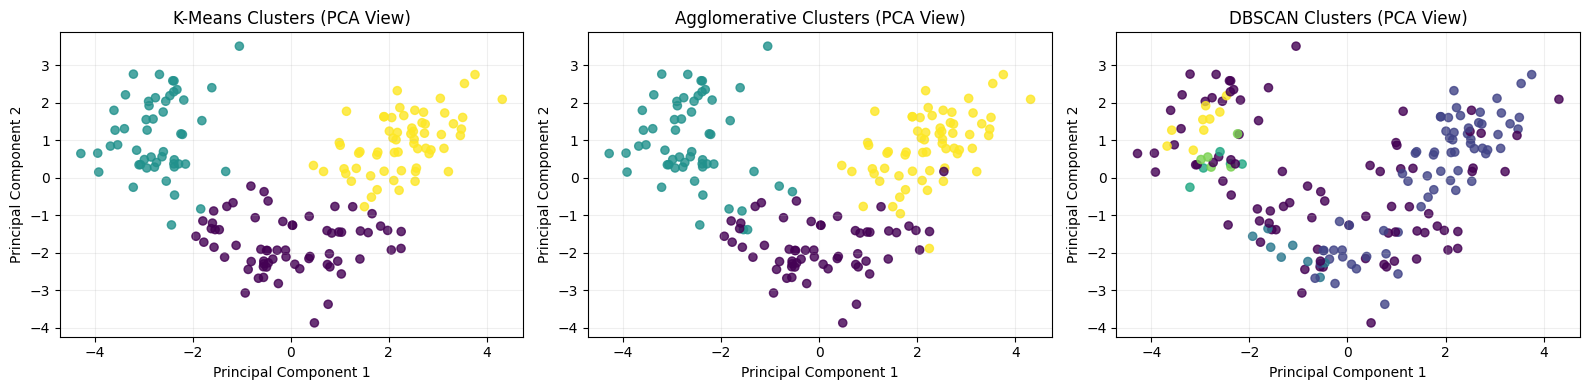

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained variance by first two principal components:")
print("PC1:", round(explained_variance[0], 4))
print("PC2:", round(explained_variance[1], 4))
print("Total explained variance:", round(explained_variance.sum(), 4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cluster_results = [
    ("K-Means", kmeans_labels),
    ("Agglomerative", agg_labels),
    ("DBSCAN", dbscan_labels)
]

for ax, (name, labels) in zip(axes, cluster_results):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=35,
        alpha=0.8
    )
    ax.set_title(f"{name} Clusters (PCA View)")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# **11. Compare Cluster Assignments**

Compare the number of observations assigned to each cluster. Cluster labels are arbitrary identifiers: cluster 0 in one algorithm does not necessarily represent the same group as cluster 0 in another algorithm.

In [ ]:
cluster_size_tables = {}

for name, labels in cluster_results:
    counts = pd.Series(labels).value_counts().sort_index()
    cluster_size_tables[name] = counts

for name, counts in cluster_size_tables.items():
    print("=" * 45)
    print(f"{name} cluster sizes")
    print("=" * 45)
    display(counts.rename("Number of Observations").to_frame())

K-Means cluster sizes


,Number of Observations
0,65
1,51
2,62


Agglomerative cluster sizes


,Number of Observations
0,58
1,56
2,64


DBSCAN cluster sizes


,Number of Observations
-1,85
0,66
1,8
2,5
3,5
4,9


# **12. Optional External Comparison with Original Labels**

The original Wine dataset includes class labels. These labels were not used to train any clustering algorithm. For an optional external comparison, Adjusted Rand Index (ARI) can measure agreement between discovered clusters and the known classes.

ARI is not a clustering quality metric based only on feature geometry. It is included only as an additional comparison because reference labels are available in this educational dataset.

In [ ]:
from sklearn.metrics import adjusted_rand_score

ari_results = pd.DataFrame([
    {
        "Model": "K-Means",
        "Adjusted Rand Index": adjusted_rand_score(original_labels, kmeans_labels)
    },
    {
        "Model": "Agglomerative",
        "Adjusted Rand Index": adjusted_rand_score(original_labels, agg_labels)
    },
    {
        "Model": "DBSCAN",
        "Adjusted Rand Index": adjusted_rand_score(original_labels, dbscan_labels)
    }
])

display(ari_results.round(4))
print("Note: Original class labels were not used during clustering.")

,Model,Adjusted Rand Index
0,K-Means,0.8975
1,Agglomerative,0.7899
2,DBSCAN,0.2205


Note: Original class labels were not used during clustering.


# **13. Comparative Analysis of Clustering Algorithms**

| Algorithm | Main idea | Strengths | Limitations | Suitable applications |
|---|---|---|---|---|
| K-Means | Assigns observations to the nearest centroid. | Simple, efficient, and easy to interpret. | Requires K in advance; sensitive to outliers and cluster shape. | Customer segmentation and compact, well-separated groups. |
| Agglomerative | Repeatedly merges the closest clusters. | Shows hierarchical grouping and supports different linkage methods. | Can be computationally expensive and sensitive to linkage choice. | Small-to-medium datasets where hierarchical structure is useful. |
| DBSCAN | Finds dense regions and marks sparse observations as noise. | Does not require a predefined cluster count; can find irregular shapes. | Sensitive to `eps` and `min_samples`; struggles with varying densities and high dimensions. | Spatial data, anomaly/noise identification, and irregularly shaped clusters. |

### Interpretation guidelines

- Compare Silhouette Scores; higher values generally indicate better separation and cohesion.
- Compare Davies-Bouldin Index; lower values generally indicate better clustering.
- Check the number and sizes of clusters to identify very small or unbalanced groups.
- Inspect the PCA plots for overlap and visible structure.
- For DBSCAN, always consider the number of noise observations and whether enough clusters were found to calculate metrics.
- Do not assume that the algorithm with the best single metric necessarily produces the most meaningful real-world groups.

# **14. Result and Analysis**

After executing the notebook, use the actual metric table, cluster sizes, and PCA plots to write your observations.

- K-Means formed the selected number of centroid-based clusters.
- Agglomerative Clustering formed a hierarchy and returned the requested number of groups.
- DBSCAN formed density-based clusters and may mark some observations as noise.
- Silhouette Score measured how well observations fit within their assigned clusters compared with other clusters.
- Davies-Bouldin Index measured within-cluster spread relative to separation between clusters.
- PCA plots provided a two-dimensional visual inspection of the clustering assignments.
- The most suitable algorithm depends on cluster shape, density, noise, dataset size, and the intended application.

**Important:** Do not insert assumed metric values. Use the numerical outputs generated by your executed notebook. If DBSCAN produces fewer than two non-noise clusters, its validity metrics will be shown as unavailable.

# **15. Potential Improvements and Further Research**

- Tune K-Means using multiple initialization settings and a broader range of K values.
- Explore DBSCAN parameter values using a k-distance plot and systematic search.
- Compare additional methods such as Gaussian Mixture Models, Mean Shift, and Spectral Clustering.
- Try different linkage methods for Agglomerative Clustering.
- Evaluate cluster stability across different samples and random seeds.
- Use domain knowledge to interpret the chemical characteristics of each cluster.
- Explore additional dimensionality-reduction methods for visualization.
- Test clustering on larger real-world datasets and investigate computational scalability.

# **16. Ethical Considerations and Limitations**

- Clusters are mathematical groupings and should not automatically be treated as meaningful real-world categories.
- Results depend on feature selection, scaling, distance measures, and algorithm parameters.
- The Wine dataset is limited in size and may not represent all wines or production settings.
- Incorrect interpretation of clusters can lead to misleading business or scientific conclusions.
- Data collection and use should respect privacy, consent, and applicable data governance requirements.
- Any real-world decisions based on clusters should be validated with domain experts and additional evidence.

# **Conclusion**

In this practical, clustering algorithms were implemented on the Wine dataset to discover groups of observations with similar chemical measurements. K-Means, Agglomerative Clustering, and DBSCAN were applied to standardized features.

The clustering results were evaluated using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score where valid. PCA was used to visualize the clusters in two dimensions, and cluster sizes and noise observations were compared.

The experiment demonstrated that K-Means is useful for compact centroid-based groups, Agglomerative Clustering is useful for hierarchical grouping, and DBSCAN can identify dense regions and noise. The most appropriate method depends on the structure and density of the data.

Thus, the practical provided an understanding of unsupervised learning, clustering implementation, and clustering quality evaluation.